*Mathematical Foundations of Robotics · Chapter 2 — Spatial Descriptions and Transformations*

# 2.1 Positions, Orientations and Frames

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/02-spatial-descriptions-and-transformations/2.1-positions-orientations-and-frames.ipynb)

A robot can act on the world only if it can say *where* things are. This section builds the vocabulary for
that statement: the **position vector** of a point, the **rotation matrix** that describes the orientation of a
body, and the **frame** that combines the two. Every later chapter — kinematics, Jacobians, dynamics and
control — is written in this language.

| | |
|:--|:--|
| **Primary reading** | Craig, *Introduction to Robotics: Mechanics and Control*, 3rd ed., §2.1–2.2 |
| **Parallel reading** | Lynch & Park, *Modern Robotics*, §3.1–3.2.1 · Spong, Hutchinson & Vidyasagar, *Robot Modeling and Control*, 2nd ed., Ch. 2 · Siciliano et al., *Robotics: Modelling, Planning and Control*, §2.1–2.2 · Corke, *Robotics, Vision and Control*, Ch. 2 |
| **Lectures** | [Prof. G. C. Nandi, Lecture 6 — Basics of spatial transformation](https://www.youtube.com/watch?v=WHIlBbJtdxk) · [Prof. G. C. Nandi, Lecture 7 — Basics of rotational transformation](https://www.youtube.com/watch?v=588iwEM-Dto) · [ThatsEngineering — Spatial descriptions and transformation matrices](https://www.youtube.com/watch?v=4Y1_y9DI_Hw) · [Modern Robotics 3.2.1 Rotation matrices (part 1)](https://www.youtube.com/watch?v=OZucG1DY_sY) |
| **Prerequisites** | [Mathematics Primer M1 (vectors) and M2 (matrices)](../../math-primer/README.md) |
| **Study time** | about 2½ hours, including the exercises |

## Learning objectives

After working through this notebook you should be able to:

1. state Craig's leading-superscript notation and read expressions such as ${}^{A}P$ and ${}^{A}_{B}R$ without ambiguity;
2. write the position of a point as a vector of projections onto the axes of a chosen frame;
3. construct the rotation matrix of one frame relative to another from the unit vectors of its axes, and interpret each entry as a direction cosine;
4. prove and use the defining properties of rotation matrices: $R^{\mathsf T}R = I$, $\det R = +1$, and only three independent parameters;
5. derive the three elementary rotations $R_X(\theta)$, $R_Y(\theta)$, $R_Z(\theta)$ and explain the sign pattern of $R_Y$;
6. describe a frame as the pair $\{{}^{A}_{B}R,\ {}^{A}P_{BORG}\}$, and build the same frame in the MuJoCo simulator.

## Contents

1. [Why robotics needs spatial descriptions](#1.-Why-robotics-needs-spatial-descriptions)
2. [Coordinate frames and notation](#2.-Coordinate-frames-and-notation)
3. [Description of a position](#3.-Description-of-a-position)
4. [Description of an orientation: the rotation matrix](#4.-Description-of-an-orientation:-the-rotation-matrix)
5. [Properties of rotation matrices](#5.-Properties-of-rotation-matrices)
6. [Elementary (principal-axis) rotations](#6.-Elementary-(principal-axis)-rotations)
7. [Description of a frame](#7.-Description-of-a-frame)
8. [Frames in simulation: MuJoCo, including two real robots](#8.-Frames-in-simulation:-MuJoCo)
9. [Worked examples](#9.-Worked-examples)
10. [Summary, common mistakes and exercises](#10.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

## 1. Why robotics needs spatial descriptions

Consider an industrial arm asked to pick a part from a conveyor. A camera mounted above the conveyor reports
that the part lies at $(0.20,\ 0.10,\ 0.50)$ metres. The numbers are meaningless until we know *what they are
measured from*: they are coordinates in the **camera's** frame, whereas the arm's controller needs them in the
frame of its **base**. Before the arm can move, the controller must therefore answer a purely geometric
question — *where is that point, described relative to the base?* — and must also know how the part is
*turned*, because the gripper has to approach it with the correct orientation.

Robotics answers such questions by a single idea. We attach a **coordinate frame** to every object of
interest — the workcell (the *universe* or *world* frame), the robot base, each link, the gripper, the camera,
the part — and we describe every object by the **position and orientation of its frame relative to another
frame**. Because the objects are treated as **rigid bodies** (the distance between any two of their points never
changes), the pose of one attached frame determines the location of every point of the body. A description of
the robot thus reduces to a description of a handful of frames, and the mathematics of this chapter is the
mathematics of describing, combining and inverting such descriptions.

> **Key idea.** *Position* is described by a $3\times1$ vector, *orientation* by a $3\times3$ rotation matrix,
> and a *frame* by both together. All three only have meaning relative to a reference frame, which must
> always be named.

## 2. Coordinate frames and notation

A **coordinate frame** is an origin together with three mutually perpendicular unit vectors
$\hat X,\ \hat Y,\ \hat Z$. Throughout this book every frame is **right-handed**: $\hat X \times \hat Y = \hat Z$.
Frames are written in braces, $\{A\}$, $\{B\}$, and so on.

Craig's notation places the **reference frame as a leading superscript** and the **described frame as a
leading subscript**. Reading the symbols correctly prevents most errors in multi-frame problems, so it is worth
memorising the following table.

| Symbol | Read as | Size |
|:--|:--|:--|
| ${}^{A}P$ | the point $P$, written in the coordinates of frame $\{A\}$ | $3\times1$ |
| ${}^{A}\hat X_B$ | the unit $X$ axis of $\{B\}$, written in $\{A\}$ | $3\times1$ |
| ${}^{A}_{B}R$ | the orientation of $\{B\}$ described relative to $\{A\}$ | $3\times3$ |
| ${}^{A}P_{BORG}$ | the origin of $\{B\}$, written in $\{A\}$ | $3\times1$ |
| ${}^{A}_{B}T$ | the pose (position and orientation) of $\{B\}$ relative to $\{A\}$ | $4\times4$ (Section 2.3) |

The notation behaves like a chain of fractions: in a product such as ${}^{A}_{B}R\,{}^{B}_{C}R = {}^{A}_{C}R$ the
inner, adjacent "$B$"s *cancel*. If the inner indices of a product do not match, the expression is almost
certainly wrong.

*Other books.* Lynch & Park write $R_{ab}$ for ${}^{a}_{b}R$ and $p_a$ for ${}^{a}p$; Spong et al. write $R^0_1$
for ${}^{0}_{1}R$; Siciliano et al. write $R^0_1$ as well. The meaning is identical: the frame being described
is the "lower" index, the frame it is described in is the "upper" index.

## 3. Description of a position

Once a frame $\{A\}$ has been chosen, any point in space is located by a **position vector** — the arrow from
the origin of $\{A\}$ to the point — expressed by its three components along the axes of $\{A\}$:

$$
{}^{A}P = \begin{bmatrix} p_x \\ p_y \\ p_z \end{bmatrix},
\qquad
p_x = {}^{A}P\cdot\hat X_A,\quad p_y = {}^{A}P\cdot\hat Y_A,\quad p_z = {}^{A}P\cdot\hat Z_A .
$$

Each component is the **orthogonal projection** of the arrow onto one axis; this is the only fact needed to
derive every result in this section. The same physical point has *different* coordinates in different frames,
which is exactly why a position vector written without its leading superscript is ambiguous. The figure below
shows a point $P$ and the three projections that make up ${}^{A}P$.

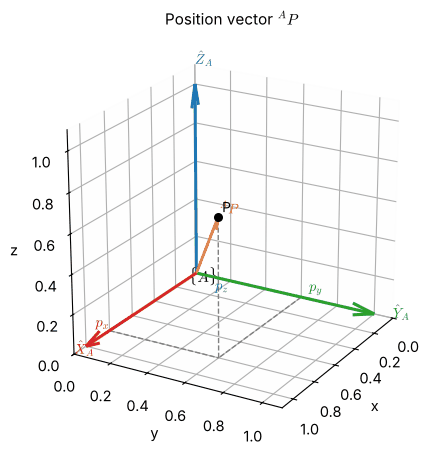

^A P = [0.8 0.6 0.7]    |P| = 1.2207


In [2]:
P = np.array([0.8, 0.6, 0.7])                       # a point, in frame {A}

ax = new_axes3d(lim=((0, 1.1), (0, 1.1), (0, 1.1)), title=r"Position vector ${}^{A}P$", azim=30)
draw_frame(ax, np.eye(3), name="A", length=1.0)
draw_vector(ax, [0, 0, 0], P, label=r"${}^{A}P$")
draw_point(ax, P, label="P")
# dashed construction lines showing the three projections
x, y, z = P
for a, b in [([x, 0, 0], [x, y, 0]), ([0, y, 0], [x, y, 0]), ([x, y, 0], [x, y, z])]:
    ax.plot(*np.array([a, b]).T, ls="--", color="grey", lw=1)
ax.text(x, -0.08, 0, r"$p_x$", color=AXIS_COLORS["x"]); ax.text(-0.08, y, 0, r"$p_y$", color=AXIS_COLORS["y"])
ax.text(x + 0.03, y, z / 2, r"$p_z$", color=AXIS_COLORS["z"])
plt.show()
print("^A P =", P, "   |P| =", np.linalg.norm(P).round(4))

## 4. Description of an orientation: the rotation matrix

A point has no orientation, but a body does. To describe the orientation of a body we attach a frame $\{B\}$
to it and write the three unit axes of $\{B\}$ in the coordinates of $\{A\}$. Stacking these three column
vectors side by side gives the **rotation matrix** of $\{B\}$ relative to $\{A\}$:

$$
{}^{A}_{B}R =
\begin{bmatrix} {}^{A}\hat X_B & {}^{A}\hat Y_B & {}^{A}\hat Z_B \end{bmatrix}
=
\begin{bmatrix}
\hat X_B\cdot\hat X_A & \hat Y_B\cdot\hat X_A & \hat Z_B\cdot\hat X_A \\
\hat X_B\cdot\hat Y_A & \hat Y_B\cdot\hat Y_A & \hat Z_B\cdot\hat Y_A \\
\hat X_B\cdot\hat Z_A & \hat Y_B\cdot\hat Z_A & \hat Z_B\cdot\hat Z_A
\end{bmatrix}.
$$

The second form follows from Section 3: each component of a vector is its dot product with an axis of the
reference frame. Because the dot product of two unit vectors is the cosine of the angle between them, the
nine entries are called **direction cosines**. A useful verbal reading of the entry in row $i$, column $j$ is:

> $r_{ij}$ = "how much of axis $j$ of $\{B\}$ lies along axis $i$ of $\{A\}$".

**Rows versus columns.** Reading the same matrix by *rows* gives the axes of $\{A\}$ written in $\{B\}$; for
instance row 1 is $({}^{B}\hat X_A)^{\mathsf T}$. But "the axes of $\{A\}$ written in $\{B\}$" is, by definition,
${}^{B}_{A}R$. Therefore

$$
{}^{B}_{A}R = {}^{A}_{B}R^{\mathsf T}.
$$

This single observation — that the inverse of a rotation is its transpose — is used on almost every page of
robotics. The figure shows a frame $\{B\}$ (solid) inside $\{A\}$ (faded); the orange segment is the projection
of $\hat X_B$ onto $\hat X_A$, i.e. the entry $r_{11}$.

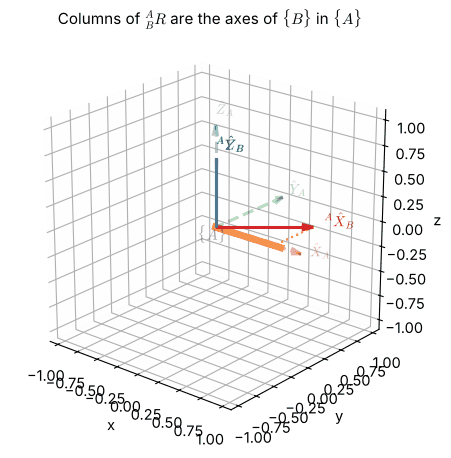

<IPython.core.display.Math object>

r11 = X_B . X_A = 0.766 -> angle between X_B and X_A = 40.0 deg


In [3]:
def Rz(t):
    """Rotation by t (radians) about Z — derived in Section 6."""
    c, s = np.cos(t), np.sin(t)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])

def Rx(t):
    c, s = np.cos(t), np.sin(t)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])

R_AB = Rz(deg(40)) @ Rx(deg(25))          # an example orientation of {B} relative to {A}

ax = new_axes3d(lim=1.1, title=r"Columns of ${}^{A}_{B}R$ are the axes of $\{B\}$ in $\{A\}$", azim=-50)
draw_frame(ax, np.eye(3), name="A", alpha=0.35, ls="--")
draw_frame(ax, R_AB, name=None, length=0.9, label_axes=False)
for i, a in enumerate("XYZ"):
    ax.text(*(1.0 * R_AB[:, i]), rf"${{}}^A\hat {a}_B$", color=list(AXIS_COLORS.values())[i])
r11 = R_AB[0, 0]
ax.plot([0, r11], [0, 0], [0, 0], color="#ff7f0e", lw=5, alpha=0.8)
ax.plot(*np.array([R_AB[:, 0] * 0.9, [r11 * 0.9, 0, 0]]).T, ls=":", color="#ff7f0e")
plt.show()
display(Math(matrix_to_latex(R_AB, 4, r"{}^{A}_{B}R")))
print("r11 = X_B . X_A =", R_AB[0, 0].round(4),
      "-> angle between X_B and X_A =", np.degrees(np.arccos(R_AB[0, 0])).round(2), "deg")

## 5. Properties of rotation matrices

The structure of ${}^{A}_{B}R$ — three mutually perpendicular unit columns forming a right-handed set — has
four consequences that we shall use constantly.

> **Theorem 2.1 (properties of rotation matrices).** Let $R = {}^{A}_{B}R$. Then
> 1. **Orthonormality.** $R^{\mathsf T}R = I$, hence $R^{-1} = R^{\mathsf T}$.
> 2. **Proper rotation.** $\det R = +1$.
> 3. **Group structure.** The set of all such matrices, the *special orthogonal group* $SO(3)$, is closed under
>    multiplication, contains $I$ and contains the inverse of each element; but multiplication is **not
>    commutative**: in general $R_1R_2 \neq R_2R_1$.
> 4. **Three degrees of freedom.** Nine entries subject to six independent constraints leave only **three**
>    independent parameters.

*Proof.* (1) Entry $(i,j)$ of $R^{\mathsf T}R$ is the dot product of columns $i$ and $j$ of $R$, which is $1$
when $i=j$ (unit vectors) and $0$ otherwise (perpendicular vectors). (2) From (1),
$\det(R^{\mathsf T}R) = (\det R)^2 = 1$, so $\det R = \pm1$. The determinant equals the scalar triple product of
the columns, $\hat X_B\cdot(\hat Y_B\times\hat Z_B)$, which is $+1$ for a right-handed frame; $\det R=-1$ would
describe a mirror image, which no physical motion can produce. (3) If $R_1,R_2\in SO(3)$ then
$(R_1R_2)^{\mathsf T}(R_1R_2) = R_2^{\mathsf T}R_1^{\mathsf T}R_1R_2 = I$ and
$\det(R_1R_2) = \det R_1\det R_2 = 1$; non-commutativity is shown by example in Section 2.2. (4) The
constraints are three "unit length" conditions and three "perpendicular pair" conditions. $\blacksquare$

Two further facts follow and will reappear in Section 2.5:

* rotations **preserve lengths, angles and cross products**: $\lVert R\mathbf v\rVert = \lVert\mathbf v\rVert$,
  $(R\mathbf u)\cdot(R\mathbf v) = \mathbf u\cdot\mathbf v$ and $R(\mathbf u\times\mathbf v) = (R\mathbf u)\times(R\mathbf v)$;
* every rotation has an **eigenvalue equal to 1**. Its eigenvector is left unchanged by the rotation and is
  therefore the **axis of rotation** (Euler's rotation theorem). The other two eigenvalues are $e^{\pm i\theta}$,
  so that $\operatorname{tr}R = 1 + 2\cos\theta$, where $\theta$ is the angle turned about the axis.

The cell below checks every one of these statements numerically for the matrix of the previous figure.

In [4]:
R = R_AB
u, v = np.array([1.0, 2.0, -0.5]), np.array([0.3, -1.0, 2.0])
eigvals, eigvecs = np.linalg.eig(R)
axis = np.real(eigvecs[:, np.argmin(abs(eigvals - 1))])
theta = np.arccos((np.trace(R) - 1) / 2)

checks = {
    "R^T R = I":                         np.allclose(R.T @ R, np.eye(3)),
    "det R = +1":                        np.isclose(np.linalg.det(R), 1.0),
    "R^-1 = R^T":                        np.allclose(np.linalg.inv(R), R.T),
    "|Rv| = |v|":                        np.isclose(np.linalg.norm(R @ v), np.linalg.norm(v)),
    "(Ru).(Rv) = u.v":                   np.isclose((R @ u) @ (R @ v), u @ v),
    "R(u x v) = Ru x Rv":                np.allclose(R @ np.cross(u, v), np.cross(R @ u, R @ v)),
    "R axis = axis (eigenvalue 1)":      np.allclose(R @ axis, axis),
    "tr R = 1 + 2 cos(theta)":           np.isclose(np.trace(R), 1 + 2 * np.cos(theta)),
}
for name, ok in checks.items():
    print(f"{'✔' if ok else '✘'}  {name}")
print("\neigenvalues:", np.round(eigvals, 4))
print("rotation axis:", axis.round(4), "  angle:", np.degrees(theta).round(2), "deg")

✔  R^T R = I
✔  det R = +1
✔  R^-1 = R^T
✔  |Rv| = |v|
✔  (Ru).(Rv) = u.v
✔  R(u x v) = Ru x Rv
✔  R axis = axis (eigenvalue 1)
✔  tr R = 1 + 2 cos(theta)

eigenvalues: [0.6833+0.7301j 0.6833-0.7301j 1.    +0.j    ]
rotation axis: [0.5111 0.186  0.8391]   angle: 46.9 deg


## 6. Elementary (principal-axis) rotations

The simplest orientations are those obtained by turning $\{B\}$ about one axis of $\{A\}$. Suppose $\{B\}$
starts coincident with $\{A\}$ and is rotated by an angle $\theta$ about the common $\hat Z$ axis (positive
$\theta$ counter-clockwise when viewed from the tip of $\hat Z$, by the right-hand rule). The figure below shows
the view looking down $\hat Z$. The new axis $\hat X_B$ makes angle $\theta$ with $\hat X_A$ and $90^\circ-\theta$ with
$\hat Y_A$, so its projections are $\cos\theta$ and $\sin\theta$; similarly $\hat Y_B$ projects to
$-\sin\theta$ and $\cos\theta$; and $\hat Z_B = \hat Z_A$.

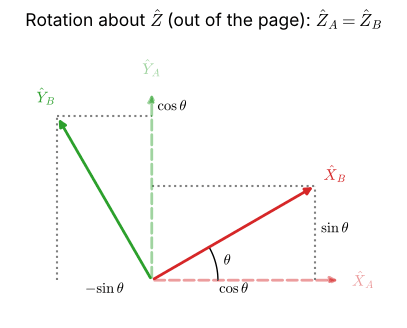

In [5]:
th = deg(30)
fig, ax = plt.subplots(figsize=(5, 4.6))
draw_frame_2d(ax, 0.0, name="A", alpha=0.45, ls="--")
draw_frame_2d(ax, th, name="B")
c, s = np.cos(th), np.sin(th)
ax.plot([c, c], [0, s], ":", color="grey"); ax.plot([0, c], [s, s], ":", color="grey")
ax.plot([-s, -s], [0, c], ":", color="grey"); ax.plot([-s, 0], [c, c], ":", color="grey")
ax.text(c / 2, -0.07, r"$\cos\theta$", ha="center"); ax.text(c + 0.03, s / 2, r"$\sin\theta$")
ax.text(-s / 2, -0.07, r"$-\sin\theta$", ha="center"); ax.text(0.03, c + 0.03, r"$\cos\theta$")
arc = np.linspace(0, th, 30)
ax.plot(0.35 * np.cos(arc), 0.35 * np.sin(arc), color="k", lw=1); ax.text(0.38, 0.08, r"$\theta$")
ax.set_xlim(-0.75, 1.3); ax.set_ylim(-0.2, 1.3); ax.set_aspect("equal"); ax.grid(False); ax.set_axis_off()
ax.set_title(r"Rotation about $\hat Z$ (out of the page): $\hat Z_A = \hat Z_B$")
plt.show()

Stacking the three columns gives $R_Z(\theta)$. The other two elementary rotations follow by the same argument,
or simply by cycling the axis labels $x\to y\to z\to x$ (writing $c\theta = \cos\theta$, $s\theta = \sin\theta$):

$$
R_X(\theta)=\begin{bmatrix}1&0&0\\0&c\theta&-s\theta\\0&s\theta&c\theta\end{bmatrix},\qquad
R_Y(\theta)=\begin{bmatrix}c\theta&0&s\theta\\0&1&0\\-s\theta&0&c\theta\end{bmatrix},\qquad
R_Z(\theta)=\begin{bmatrix}c\theta&-s\theta&0\\s\theta&c\theta&0\\0&0&1\end{bmatrix}.
$$

> ⚠️ **The sign in $R_Y$.** In $R_Y$ the $+\sin\theta$ sits at the *top right* and $-\sin\theta$ at the bottom
> left — the opposite pattern to $R_X$ and $R_Z$. The reason is the cyclic order $x\to y\to z\to x$: a positive
> rotation about $\hat Y$ turns $\hat Z$ *towards* $\hat X$, so $\hat Z_B$ gains a $+\sin\theta$ component along
> $\hat X_A$ (top right of the third column). A quick self-check: every elementary rotation must have
> determinant $+1$, and $R_Y(90^\circ)$ must send $\hat Z$ to $\hat X$.

We now implement $R_Y$ (we already wrote $R_X$ and $R_Z$ above) and test the three functions against the
repository's reference library `rgkit.transforms`, which is used by all later chapters.

In [6]:
def Ry(t):
    c, s = np.cos(t), np.sin(t)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])

from rgkit import transforms as tf
for t in np.linspace(-np.pi, np.pi, 9):
    assert np.allclose(Rx(t), tf.rotx(t)) and np.allclose(Ry(t), tf.roty(t)) and np.allclose(Rz(t), tf.rotz(t))
print("Our Rx, Ry, Rz agree with rgkit.transforms for all test angles.")
print("Ry(90°) maps Z to", (Ry(deg(90)) @ [0, 0, 1]).round(6), " (should be +X)")

Our Rx, Ry, Rz agree with rgkit.transforms for all test angles.
Ry(90°) maps Z to [1. 0. 0.]  (should be +X)


### Animation: watching the direction cosines change

As $\{B\}$ turns about $\hat Z_A$, the first column of ${}^{A}_{B}R$ traces $(\cos\theta, \sin\theta, 0)$. Run the
cell to play the animation (on GitHub you see a filmstrip of key frames; the animated version is in the
[chapter README](README.md)).

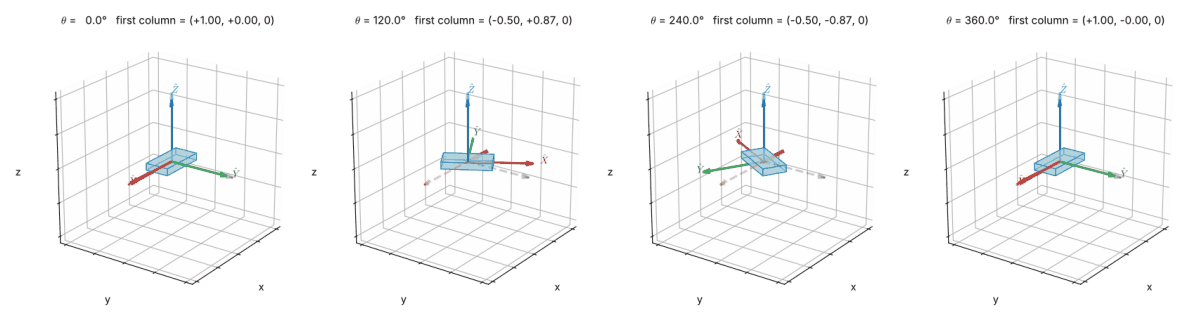

In [7]:
fig = plt.figure(figsize=(5.4, 5.0))
ax = fig.add_subplot(111, projection="3d")

def update(theta):
    ax.cla()
    new_axes3d(ax, lim=1.1, title=rf"$\theta$ = {np.degrees(theta):5.1f}°   first column = "
               rf"({np.cos(theta):+.2f}, {np.sin(theta):+.2f}, 0)", ticks=False)
    draw_frame(ax, np.eye(3), name="A", alpha=0.3, ls="--", label_axes=False)
    draw_frame(ax, Rz(theta), length=0.9)
    draw_box(ax, np.block([[Rz(theta), np.zeros((3, 1))], [0, 0, 0, 1]]), size=(0.7, 0.35, 0.1))
    ax.plot([0, np.cos(theta) * 0.9], [0, 0], [0, 0], color="#ff7f0e", lw=4)

animate(fig, update, np.linspace(0, 2 * np.pi, 37), interval=90, gif="assets/2.1-rotation-about-z.gif")

### Interactive exploration

Drag the sliders to rotate $\{B\}$ first about $\hat X$, then $\hat Y$, then $\hat Z$ (the meaning of the
*order* is the subject of Section 2.2). Watch the matrix: its columns are always unit length and mutually
perpendicular, and its determinant never leaves $+1$.

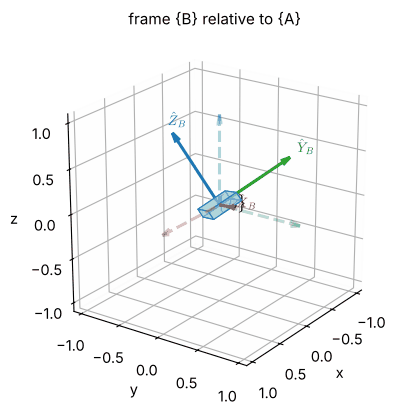

<IPython.core.display.Math object>

In [8]:
def explore(about_x=30.0, about_y=-20.0, about_z=45.0):
    R = Rz(deg(about_z)) @ Ry(deg(about_y)) @ Rx(deg(about_x))
    ax = new_axes3d(lim=1.1, title="frame {B} relative to {A}", figsize=(4.6, 4.6))
    draw_frame(ax, np.eye(3), name="A", alpha=0.3, ls="--", label_axes=False)
    draw_frame(ax, R, name="B", length=0.9)
    draw_box(ax, np.block([[R, np.zeros((3, 1))], [0, 0, 0, 1]]), size=(0.7, 0.35, 0.1))
    plt.show()
    display(Math(matrix_to_latex(R, 3, r"{}^{A}_{B}R") + rf"\qquad \det R = {np.linalg.det(R):.6f}"))

interact(explore,
         about_x=widgets.FloatSlider(30, min=-180, max=180, step=5, description="about X (°)"),
         about_y=widgets.FloatSlider(-20, min=-180, max=180, step=5, description="about Y (°)"),
         about_z=widgets.FloatSlider(45, min=-180, max=180, step=5, description="about Z (°)"));

## 7. Description of a frame

A **frame** is the set of four vectors that gives both position and orientation:

$$
\{B\} = \left\{\, {}^{A}_{B}R,\ \ {}^{A}P_{BORG} \,\right\}.
$$

A frame can stand for a body, a tool, a goal, a camera or a sensor. Two special cases are worth naming: a pure
**position** is a frame whose rotation is $I$, and a pure **orientation** is a frame whose origin coincides with
that of the reference frame. In drawings a frame is shown by its three axes, with an arrow from the reference
origin to its own origin. The figure below shows a typical workcell: the universe frame $\{U\}$, the robot base
$\{B\}$, a camera $\{C\}$ looking down, and a part $\{P\}$ on the table. Each is described *relative to
$\{U\}$* by a rotation and a position; Section 2.3 shows how to convert between such descriptions.

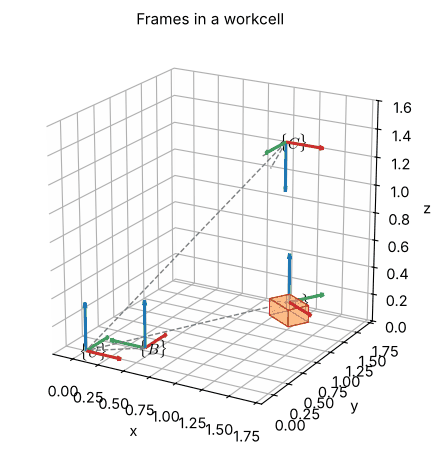

{U}:  origin in {U} = [0. 0. 0.],  det R = +1
{B}:  origin in {U} = [0.4 0.3 0. ],  det R = +1
{C}:  origin in {U} = [1.3 1.1 1.4],  det R = +1
{P}:  origin in {U} = [1.4 1.  0.3],  det R = +1


In [9]:
frames = {
    "U": (np.eye(3),                       np.zeros(3)),
    "B": (Rz(deg(90)),                     np.array([0.4, 0.3, 0.0])),
    "C": (Rx(deg(180)),                    np.array([1.3, 1.1, 1.4])),   # camera Z points down
    "P": (Rz(deg(-30)),                    np.array([1.4, 1.0, 0.3])),
}
ax = new_axes3d(lim=((-0.2, 1.8), (-0.2, 1.8), (0, 1.6)), title="Frames in a workcell", azim=-60, elev=20)
for name, (R, p) in frames.items():
    draw_frame(ax, R, p, name=name, length=0.35, label_axes=False)
    if name != "U":
        draw_vector(ax, [0, 0, 0], p, color="grey", lw=1, ls="--")
T_P = np.eye(4); T_P[:3, :3], T_P[:3, 3] = frames["P"][0], frames["P"][1] - [0, 0, 0.06]
draw_box(ax, T_P, size=(0.3, 0.2, 0.12), color="#fdae6b", edgecolor="#e6550d")
plt.show()
for name, (R, p) in frames.items():
    print(f"{{{name}}}:  origin in {{U}} = {p},  det R = {np.linalg.det(R):+.0f}")

## 8. Frames in simulation: MuJoCo

[MuJoCo](https://mujoco.org) is a physics simulator widely used in robotics research. A MuJoCo model is written
in an XML format called **MJCF**, in which every `<body>` carries its own coordinate frame, specified *relative
to its parent body* — precisely the idea of this section. One of the ways MJCF lets us specify a body's
orientation is the attribute `xyaxes="x1 x2 x3 y1 y2 y3"`, which lists **the body's X and Y axes written in the
parent frame**; MuJoCo completes $\hat Z = \hat X\times\hat Y$. In other words, `xyaxes` is the first two columns of
${}^{A}_{B}R$.

The cell below builds a model containing a faded reference frame $\{A\}$ (the world) and a body $\{B\}$ whose
`xyaxes` are taken from our matrix `R_AB`. After the model is compiled, MuJoCo reports the orientation of every
body in the world frame in `data.xmat` (a row-major $3\times3$ matrix). If our understanding is right, MuJoCo's
matrix must equal ours. See [docs/MUJOCO.md](../../docs/MUJOCO.md) for installation and a fuller introduction.

MuJoCo's orientation of body B (data.xmat):
 [[ 0.766  -0.5826  0.2717]
 [ 0.6428  0.6943 -0.3237]
 [ 0.      0.4226  0.9063]]

Agrees with our ^A_B R: True


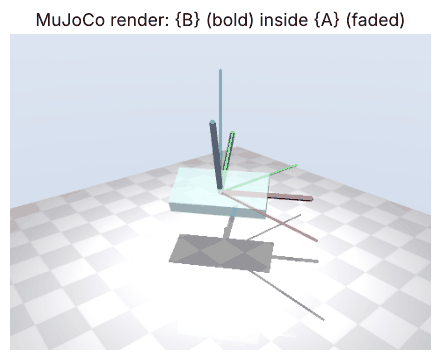

In [10]:
from rgkit import mujoco_utils as mju       # chooses an OpenGL backend, then imports MuJoCo
import mujoco

xa, ya = R_AB[:, 0], R_AB[:, 1]              # first two columns of ^A_B R
xml = f"""
<mujoco model="frame_B_in_A">
  {mju.scene_assets()}
  <worldbody>
    {mju.floor(z=-0.6)}
    {mju.frame_axes_geoms(length=0.8, radius=0.008, alpha=0.35, prefix="A_")}
    <body name="B" xyaxes="{xa[0]:.12f} {xa[1]:.12f} {xa[2]:.12f} {ya[0]:.12f} {ya[1]:.12f} {ya[2]:.12f}">
      {mju.frame_axes_geoms(length=0.6, radius=0.018, prefix="B_")}
      <geom type="box" size="0.32 0.16 0.05" rgba="0.62 0.79 0.88 0.55" contype="0" conaffinity="0"/>
    </body>
  </worldbody>
</mujoco>"""
model, data = mju.load(xml)
R_mujoco = data.body("B").xmat.reshape(3, 3)

print("MuJoCo's orientation of body B (data.xmat):\n", R_mujoco)
print("\nAgrees with our ^A_B R:", np.allclose(R_mujoco, R_AB, atol=1e-9))
img = mju.render(model, data, camera=dict(azimuth=140, elevation=-25, distance=2.6, lookat=(0, 0, 0)))
plt.figure(figsize=(5.5, 4.1)); plt.imshow(img); plt.axis("off")
plt.title("MuJoCo render: {B} (bold) inside {A} (faded)"); plt.show()

The agreement is exact to machine precision: the simulator and the hand-built matrix describe the same frame.
Note one difference of *convention* that you will meet again: MuJoCo stores orientations internally as unit
quaternions (`data.xquat`, scalar first), which we study in Section 2.5.

### 8.2 A frame on every link: two real robots

The toy body above has one frame. A real robot arm has one frame **per link**, and the whole of Chapters 2–3
is about the relations between them. The cell below loads two industrial-grade models from
[MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie) — the six-joint **Universal Robots UR5e**
and the seven-joint **Franka Emika Panda** — and asks MuJoCo to draw the frame of every body
(red $\hat X$, green $\hat Y$, blue $\hat Z$, as always). The first call downloads the models (about 60 MB, cached
afterwards; see [docs/MUJOCO.md](../../docs/MUJOCO.md)).

Two things are worth noticing. First, the frames are **not** all aligned: each link frame is oriented according
to the designer's convention, and the rotation matrix between neighbouring frames is exactly what Chapter 3
will systematise as the Denavit–Hartenberg convention. Second, the table below lists, for the UR5e, the position
of every link frame *in its parent's frame* — the vector ${}^{i-1}P_{i\,ORG}$ of the previous section. The
entries are the real link dimensions of the robot (rounded to the nearest millimetre by the model's authors):
for example the upper arm is $0.425$ m long and the forearm $0.392$ m. Chapter 3 shows how such offsets are
packaged into the four D-H parameters of each link.

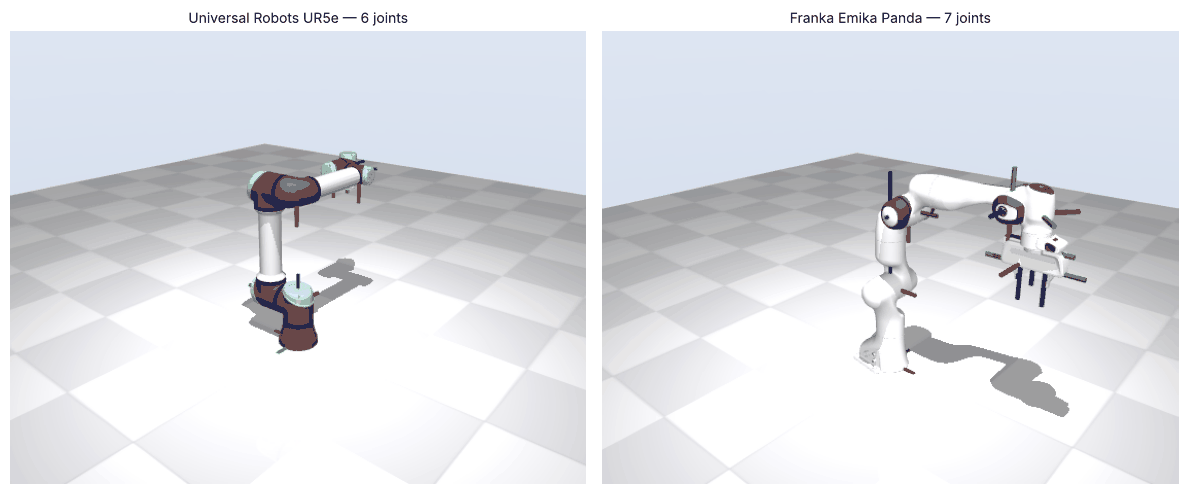

| link frame | parent frame | offset in parent frame (m) |
|:--|:--|:--|
| `base` | `world` | (+0.0000, +0.0000, +0.0000) |
| `shoulder_link` | `base` | (+0.0000, +0.0000, +0.1630) |
| `upper_arm_link` | `shoulder_link` | (+0.0000, +0.1380, +0.0000) |
| `forearm_link` | `upper_arm_link` | (+0.0000, -0.1310, +0.4250) |
| `wrist_1_link` | `forearm_link` | (+0.0000, +0.0000, +0.3920) |
| `wrist_2_link` | `wrist_1_link` | (+0.0000, +0.1270, +0.0000) |
| `wrist_3_link` | `wrist_2_link` | (+0.0000, +0.0000, +0.1000) |

Universal Robots UR5e — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/universal_robots_ur5e) (Universal Robots; licence: BSD-3-Clause)


In [11]:
from rgkit import robots
from rgkit.animation import filmstrip

views = {"ur5e": dict(azimuth=130, elevation=-22, distance=2.0, lookat=(0, 0, 0.35)),
         "panda": dict(azimuth=130, elevation=-22, distance=2.0, lookat=(0, 0, 0.45))}
shots = []
for name, cam in views.items():
    m_r, d_r = robots.load_robot(name)                    # downloads on first use, then cached
    opt = robots.frames_option(m_r, length=0.12, width=0.007)   # draw the frame of every body
    shots.append(mju.render(m_r, d_r, camera=cam, width=560, height=440, scene_option=opt))
filmstrip(shots, [robots.ROBOTS[n]["title"] + f" — {robots.ROBOTS[n]['dof']} joints" for n in views])

m_r, d_r = robots.load_robot("ur5e")
rows = ["| link frame | parent frame | offset in parent frame (m) |", "|:--|:--|:--|"]
for i in range(1, m_r.nbody):
    parent = m_r.body(m_r.body_parentid[i]).name
    rows.append(f"| `{m_r.body(i).name}` | `{parent}` | ({', '.join(f'{v:+.4f}' for v in m_r.body_pos[i])}) |")
display(Markdown("\n".join(rows)))
print(robots.describe("ur5e"))

The pose of every link in the world is stored in `data.xpos` and `data.xmat`. As a check on the chain rule of
Section 2.2, we rebuild the pose of the last link by multiplying the link-to-link rotations
${}^{i-1}_{\ \,i}R = ({}^{W}_{i-1}R)^{\mathsf T}\,{}^{W}_{i}R$ starting from the base:

In [12]:
n = m_r.nbody
R_W = [d_r.xmat[i].reshape(3, 3) for i in range(n)]
R_chain = R_W[1]                                          # world orientation of the base link
for i in range(2, n):
    R_chain = R_chain @ (R_W[i - 1].T @ R_W[i])           # multiply the link-to-link rotations
print("chain of link-to-link rotations reproduces the wrist-3 orientation:", np.allclose(R_chain, R_W[-1]))
print("wrist-3 frame, orientation in the world frame:\n", R_W[-1].round(4) + 0.0)

chain of link-to-link rotations reproduces the wrist-3 orientation: True
wrist-3 frame, orientation in the world frame:
 [[ 1.  0.  0.]
 [ 0.  0.  1.]
 [ 0. -1.  0.]]


## 9. Worked examples

**Example 2.1.1 — building a rotation matrix from axes.** The axes of a frame $\{B\}$ are known in $\{A\}$:
$\hat X_B = (0, 1, 0)$, $\hat Y_B = (0, 0, 1)$, $\hat Z_B = (1, 0, 0)$. Find ${}^{A}_{B}R$ and ${}^{B}_{A}R$ and
verify that ${}^{A}_{B}R$ is a proper rotation.

*Solution.* The columns of ${}^{A}_{B}R$ are the given vectors:

$$
{}^{A}_{B}R=\begin{bmatrix}0&0&1\\1&0&0\\0&1&0\end{bmatrix},\qquad
{}^{B}_{A}R={}^{A}_{B}R^{\mathsf T}=\begin{bmatrix}0&1&0\\0&0&1\\1&0&0\end{bmatrix}.
$$

The columns are unit vectors and mutually perpendicular. The triple product
$\hat X_B\cdot(\hat Y_B\times\hat Z_B) = (0,1,0)\cdot\big((0,0,1)\times(1,0,0)\big) = (0,1,0)\cdot(0,1,0) = 1$, so
$\det R = +1$ and $\{B\}$ is right-handed. (We shall see in Section 2.2 that this matrix equals
$R_Z(90^\circ)R_X(90^\circ)$.)

**Example 2.1.2 — is it a rotation?** Decide whether each matrix is a rotation matrix.

$$
M_1=\begin{bmatrix}0&1&0\\1&0&0\\0&0&1\end{bmatrix},\qquad
M_2=\begin{bmatrix}0.6&-0.8&0\\0.8&0.6&0\\0&0&1\end{bmatrix},\qquad
M_3=\begin{bmatrix}1&0.1&0\\0&1&0\\0&0&1\end{bmatrix}.
$$

*Solution.* $M_1$ is orthogonal but $\det M_1=-1$: it swaps $X$ and $Y$, a reflection, so it is **not** a
rotation. $M_2$ is orthonormal with $\det M_2 = 0.36+0.64 = 1$; it **is** a rotation, namely $R_Z(53.13^\circ)$.
$M_3$ has $\det M_3 = 1$, yet it is **not** a rotation: its second column $(0.1,1,0)$ has length $1.005$ and is
not perpendicular to the first column (their dot product is $0.1$). It is a *shear*. The lesson is that
$\det R = +1$ alone is not sufficient — orthonormality must be checked as well.

**Example 2.1.3 — reading direction cosines.** For ${}^{A}_{B}R = R_Z(40^\circ)R_X(25^\circ)$ (the matrix used in
the figures), find the angle between $\hat Z_B$ and $\hat Z_A$.

*Solution.* That angle's cosine is the entry $r_{33} = \hat Z_B\cdot\hat Z_A = \cos25^\circ = 0.9063$, so the
angle is $25^\circ$ — as expected, because the rotation about $\hat Z$ does not tilt the $Z$ axis; only the
$25^\circ$ rotation about $\hat X$ does.

The cell below verifies all three examples.

In [13]:
R1 = np.array([[0, 0, 1], [1, 0, 0], [0, 1, 0]])
print("Example 2.1.1:  rotation?", tf.is_rotation(R1), "  equals Rz(90)Rx(90)?",
      np.allclose(R1, Rz(deg(90)) @ Rx(deg(90))))
for name, M in {"M1": [[0, 1, 0], [1, 0, 0], [0, 0, 1]],
                "M2": [[0.6, -0.8, 0], [0.8, 0.6, 0], [0, 0, 1]],
                "M3": [[1, 0.1, 0], [0, 1, 0], [0, 0, 1]]}.items():
    M = np.array(M, float)
    print(f"Example 2.1.2:  {name}: det = {np.linalg.det(M):+.3f}, orthonormal = "
          f"{np.allclose(M.T @ M, np.eye(3))}, rotation = {tf.is_rotation(M)}")
print("                M2 angle =", np.degrees(np.arctan2(0.8, 0.6)).round(2), "deg about Z")
print("Example 2.1.3:  angle(Z_B, Z_A) =", np.degrees(np.arccos(R_AB[2, 2])).round(4), "deg")

Example 2.1.1:  rotation? True   equals Rz(90)Rx(90)? True
Example 2.1.2:  M1: det = -1.000, orthonormal = True, rotation = False
Example 2.1.2:  M2: det = +1.000, orthonormal = True, rotation = True
Example 2.1.2:  M3: det = +1.000, orthonormal = False, rotation = False
                M2 angle = 53.13 deg about Z
Example 2.1.3:  angle(Z_B, Z_A) = 25.0 deg


## 10. Summary

| Concept | Statement |
|:--|:--|
| Position | ${}^{A}P$: components are projections onto the axes of $\{A\}$ |
| Rotation matrix | ${}^{A}_{B}R = [\,{}^{A}\hat X_B\ \ {}^{A}\hat Y_B\ \ {}^{A}\hat Z_B\,]$; entries are direction cosines |
| Inverse | ${}^{B}_{A}R = {}^{A}_{B}R^{-1} = {}^{A}_{B}R^{\mathsf T}$ |
| Membership of $SO(3)$ | $R^{\mathsf T}R=I$ and $\det R=+1$; 3 independent parameters |
| Invariants | lengths, angles and cross products are preserved; eigenvalue $1$ ↔ rotation axis; $\operatorname{tr}R = 1+2\cos\theta$ |
| Elementary rotations | $R_X$, $R_Y$, $R_Z$ — note the sign pattern of $R_Y$ |
| Frame | $\{B\} = \{{}^{A}_{B}R,\ {}^{A}P_{BORG}\}$ |

### Common mistakes

* Writing a vector or matrix **without its reference frame**. ${}^{A}P$ and ${}^{B}P$ are different vectors.
* Confusing **rows and columns**: the *columns* of ${}^{A}_{B}R$ are the axes of $\{B\}$ in $\{A\}$.
* Getting the **sign of $\sin\theta$ in $R_Y$** wrong. Check that $R_Y(90^\circ)\hat Z = \hat X$.
* Accepting a matrix with $\det = -1$ as a rotation. It is a reflection.
* Mixing **degrees and radians** — `numpy` trigonometric functions expect radians.

## Exercises

**2.1.1** Show that the inverse of $R_Z(\theta)$ is $R_Z(-\theta)$ and that this equals $R_Z(\theta)^{\mathsf T}$.

<details><summary>Answer</summary>

$R_Z(-\theta)$ is obtained by replacing $s\theta$ with $-s\theta$, which swaps the off-diagonal entries — exactly the
transpose. Multiplying, $R_Z(\theta)R_Z(-\theta) = I$ because $c^2\theta+s^2\theta=1$.
</details>

**2.1.2** A frame $\{B\}$ has ${}^{A}\hat X_B = (\tfrac{1}{\sqrt2}, \tfrac{1}{\sqrt2}, 0)$ and
${}^{A}\hat Y_B = (0, 0, 1)$. Find ${}^{A}\hat Z_B$ and ${}^{A}_{B}R$.

<details><summary>Answer</summary>

$\hat Z_B = \hat X_B\times\hat Y_B = (\tfrac{1}{\sqrt2}, -\tfrac{1}{\sqrt2}, 0)$, so
${}^{A}_{B}R = \begin{bmatrix} 0.7071 & 0 & 0.7071\\ 0.7071 & 0 & -0.7071\\ 0 & 1 & 0\end{bmatrix}$, with
$\det = +1$.
</details>

**2.1.3** How many independent numbers are needed to specify the orientation of a body (a) in the plane,
(b) in space? Relate your answer to the constraints on a $2\times2$ and a $3\times3$ rotation matrix.

<details><summary>Answer</summary>

(a) One: a $2\times2$ rotation has 4 entries and 3 constraints (two unit columns, one perpendicularity).
(b) Three: 9 entries, 6 constraints.
</details>

**2.1.4** Using only the properties of Theorem 2.1, show that $\operatorname{tr}(R_X(\theta)) = 1+2\cos\theta$,
and use the trace to find the rotation angle of $M_2$ in Example 2.1.2.

<details><summary>Answer</summary>

$\operatorname{tr}R_X = 1 + c\theta + c\theta$. For $M_2$, $\operatorname{tr} = 2.2 = 1 + 2\cos\theta$ gives
$\cos\theta=0.6$, $\theta = 53.13^\circ$.
</details>

**2.1.5** (*Programming*) Write a function `is_rotation(M, tol)` that returns `True` only for proper rotation
matrices, and test it on $M_1$, $M_2$, $M_3$ and on `Rz(0.3) @ Ry(1.2)` contaminated by noise of size
$10^{-4}$. What tolerance is sensible, and why can repeated multiplication of rotation matrices in floating
point slowly destroy orthonormality?

<details><summary>Answer</summary>

Compare `M.T @ M` with `I` and `det(M)` with 1 using a tolerance a few orders above machine precision
(e.g. $10^{-9}$ for exact data, larger for measured data). Each product adds rounding error of order
$10^{-16}$; after millions of products the columns drift from unit length and perpendicularity, which is why
long computations re-orthonormalise (see `rgkit.transforms.orthonormalize`, Section 2.3).
</details>

**2.1.6** (*MuJoCo*) Modify the MuJoCo model of Section 8 so that body `B` is specified with
`zaxis="0 0 -1"` instead of `xyaxes`. What orientation does MuJoCo choose, and why is a single axis not enough
to define an orientation uniquely?

<details><summary>Answer</summary>

MuJoCo chooses the *minimal* rotation taking $\hat Z$ to $(0,0,-1)$ — a $180^\circ$ rotation about an axis
perpendicular to $\hat Z$. Any further rotation about the new $\hat Z$ would also satisfy the specification, so
one axis fixes only two of the three orientation parameters.
</details>

**2.1.7** (*Real robot*) Using `robots.load_robot('ur5e')`, how many link frames does the model contain (not
counting the world), how many joints does it have, and why are the two numbers different?

<details><summary>Answer</summary>

Seven link frames (`base`, `shoulder_link`, `upper_arm_link`, `forearm_link`, `wrist_1_link`, `wrist_2_link`,
`wrist_3_link`) but six joints: the base frame is fixed to the ground and is not moved by any joint, whereas each
joint moves the link after it. For a serial arm with $n$ joints there are $n+1$ link frames, numbered $0,\dots,n$.
</details>

## Further reading and lectures

* Craig, §2.1–2.2; Lynch & Park, §3.1 (planar) and §3.2.1; Spong et al., Ch. 2 (§2.1–2.2);
  Siciliano et al., §2.1–2.2; Corke, *RVC*, Ch. 2.
* Video: [Prof. G. C. Nandi, Lecture 6 — Basics of spatial transformation](https://www.youtube.com/watch?v=WHIlBbJtdxk); [Prof. G. C. Nandi, Lecture 7 — Basics of rotational transformation](https://www.youtube.com/watch?v=588iwEM-Dto); [ThatsEngineering — Spatial descriptions and transformation matrices](https://www.youtube.com/watch?v=4Y1_y9DI_Hw); [Modern Robotics Chapter 3 introduction: rigid-body motions](https://www.youtube.com/watch?v=29LhXWjn7Pc); [Modern Robotics 3.2.1 Rotation matrices (part 1)](https://www.youtube.com/watch?v=OZucG1DY_sY); [Modern Robotics 3.2.1 Rotation matrices (part 2)](https://www.youtube.com/watch?v=6KIPusOv5fA).
* MuJoCo documentation, [MJCF modelling — frame orientations](https://mujoco.readthedocs.io/en/stable/modeling.html#frame-orientations).

---

[Chapter contents](README.md) &nbsp;·&nbsp; [2.2 Mappings and Operators →](2.2-mappings-and-operators.ipynb)